# Relationship plots

## Learning objectives

By the end of this notebook you will be able to:

- show the relationship between two numeric variables with scatterplot
- add groups with hue, style and size
- fit and interpret regression lines with regplot and lmplot
- plot trends over time with lineplot, including uncertainty bands
- use relplot and jointplot

## Introduction

"Is y related to x?" is one of the most common questions in data analysis. Scatter plots show the
relationship; regression lines summarise it; line plots show how a value changes over time or an
ordered variable.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
RAW = "../datasets/raw/"

In [2]:
sns.set_theme(style="whitegrid")
penguins = sns.load_dataset("penguins")
tips = sns.load_dataset("tips")
fmri = sns.load_dataset("fmri")

## scatterplot

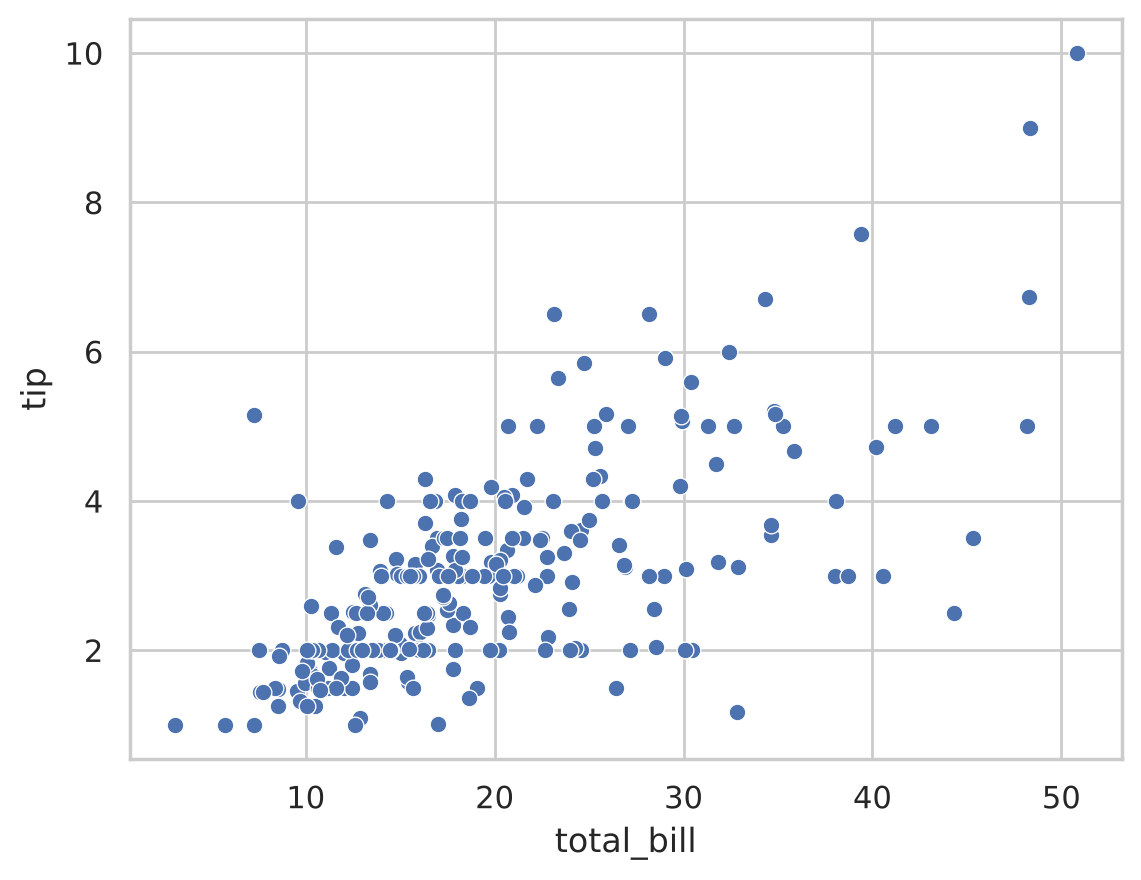

In [3]:
sns.scatterplot(data=tips, x="total_bill", y="tip")
plt.show()

**Reading it:** tips rise with the bill, roughly in a straight line, and the spread of tips widens as
bills grow (the cloud fans out). That widening matters: a single "average tip rate" fits small bills
better than large ones.

### Encoding more variables

`hue` (colour), `style` (marker) and `size` add up to three more variables. More than two usually
makes a plot hard to read.

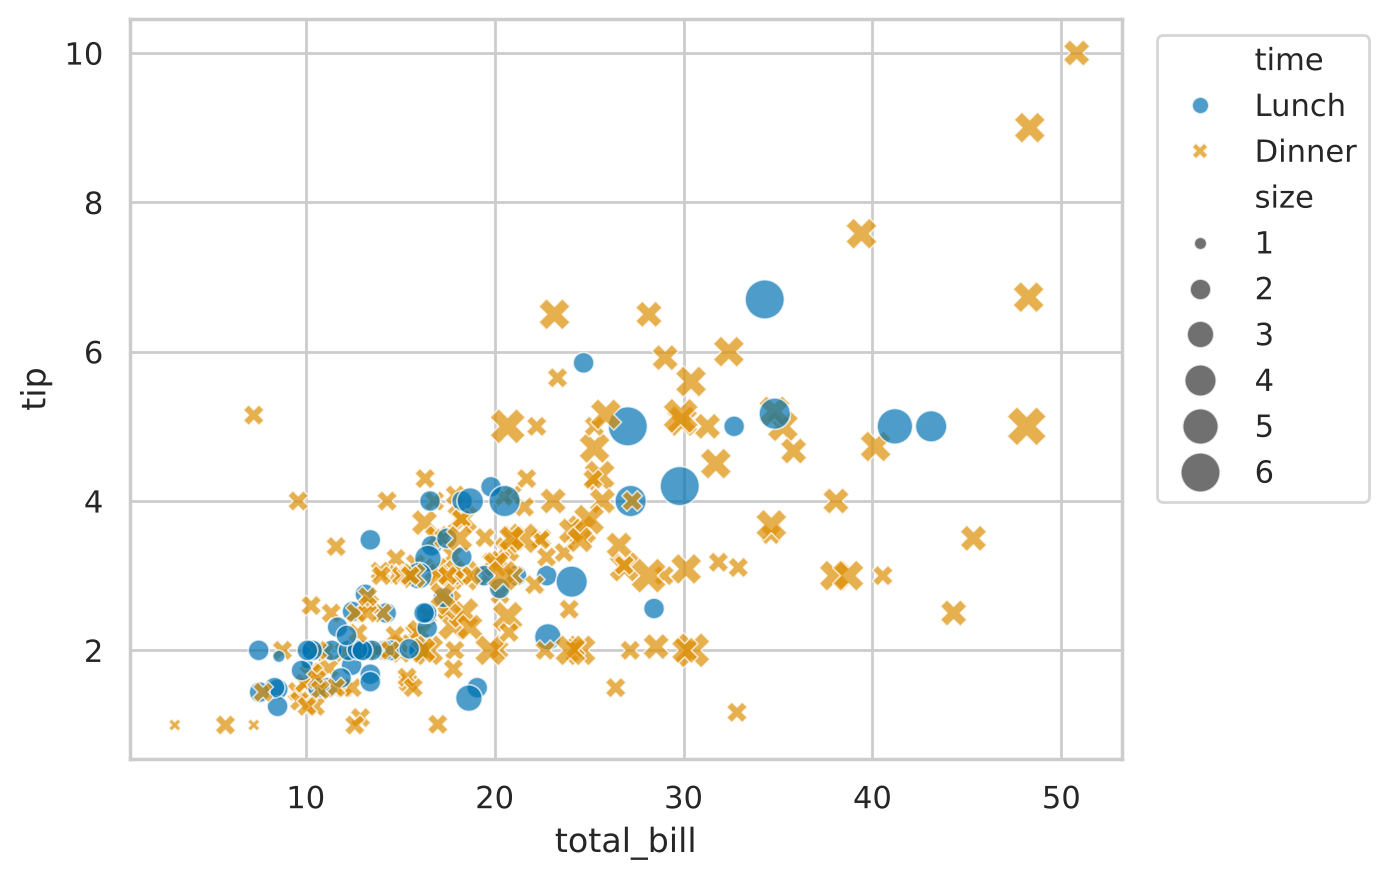

In [4]:
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", style="time", size="size",
                sizes=(20, 200), alpha=0.7, palette="colorblind")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## Regression lines: regplot and lmplot

`regplot` fits a straight line (least squares) and shades a 95% confidence band for the line.

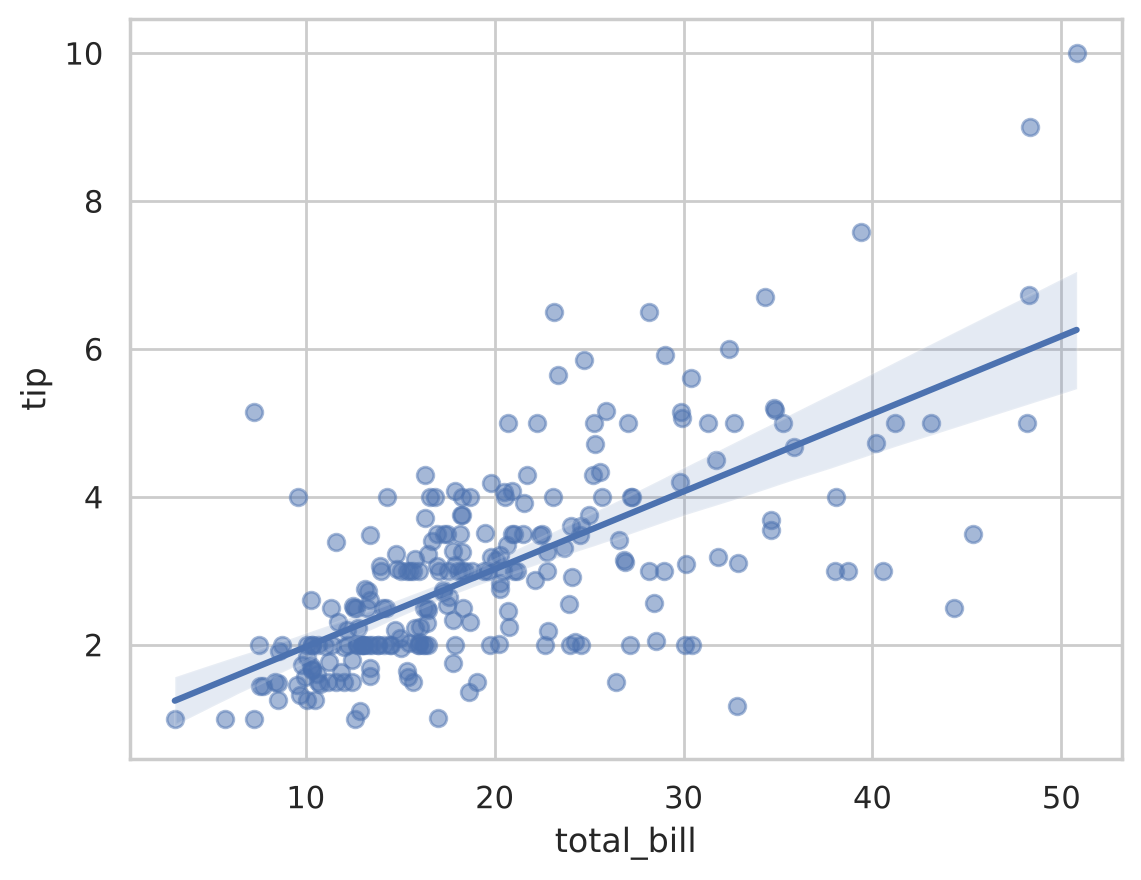

tip = 0.92 + 0.105 x total_bill   (r = 0.68, r squared = 0.46)


In [5]:
ax = sns.regplot(data=tips, x="total_bill", y="tip", scatter_kws={"alpha": 0.5})
plt.show()
slope, intercept = np.polyfit(tips["total_bill"], tips["tip"], 1)
r = tips["total_bill"].corr(tips["tip"])
print(f"tip = {intercept:.2f} + {slope:.3f} x total_bill   (r = {r:.2f}, r squared = {r ** 2:.2f})")

**Interpreting it:**

- the **slope** (about 0.105): each extra unit on the bill goes with about 0.105 more in tip, a tip rate
  of roughly 10.5% at the margin
- the **intercept** (about 0.92) is the line's value at a bill of zero, which is outside the data and
  has no real meaning here
- **r** (about 0.68) measures how tightly points follow the line; **r squared** (about 0.46) means the
  bill explains about 46% of the variation in tips
- the **shaded band** shows the uncertainty in the line's position, not where individual tips will fall

Correlation is not causation, and a line describes these data only, within the range observed.

### lmplot: separate lines per group

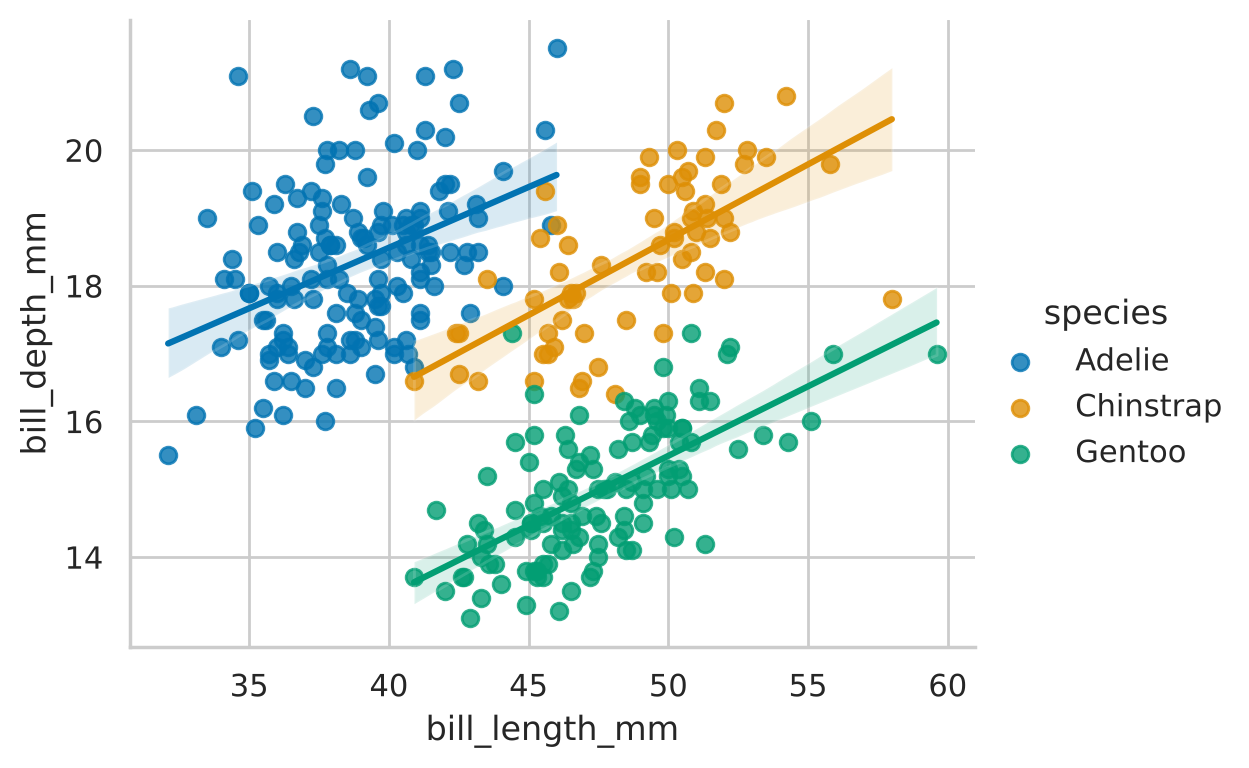

In [6]:
sns.lmplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", hue="species",
           palette="colorblind", height=4, aspect=1.3)
plt.show()

### Simpson's paradox

Fitting one line to all penguins tells the opposite story:

overall r: -0.24
species
Adelie       0.39
Chinstrap    0.65
Gentoo       0.64
Name: bill_depth_mm, dtype: float64


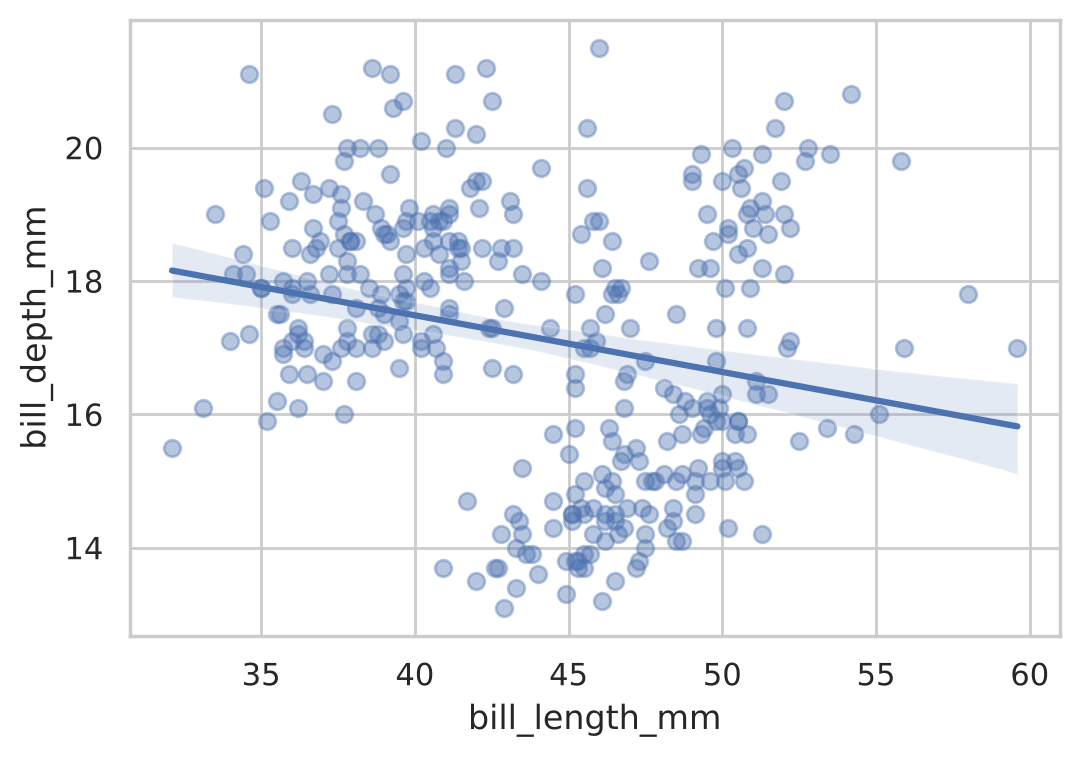

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.regplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", scatter_kws={"alpha": 0.4}, ax=ax)
print("overall r:", round(penguins["bill_length_mm"].corr(penguins["bill_depth_mm"]), 2))
print(penguins.groupby("species")[["bill_length_mm", "bill_depth_mm"]].corr().xs("bill_length_mm", level=1)["bill_depth_mm"].round(2))
plt.show()

Across all penguins, longer bills go with shallower bills (negative r). Within each species, longer
bills go with *deeper* bills (positive r). The overall line is misleading because species differ in both
measurements. Always check whether a grouping variable changes the relationship.

### Non-linear patterns

`order=2` fits a curve; `lowess=True` fits a smooth line without assuming a shape (it needs the
statsmodels package).

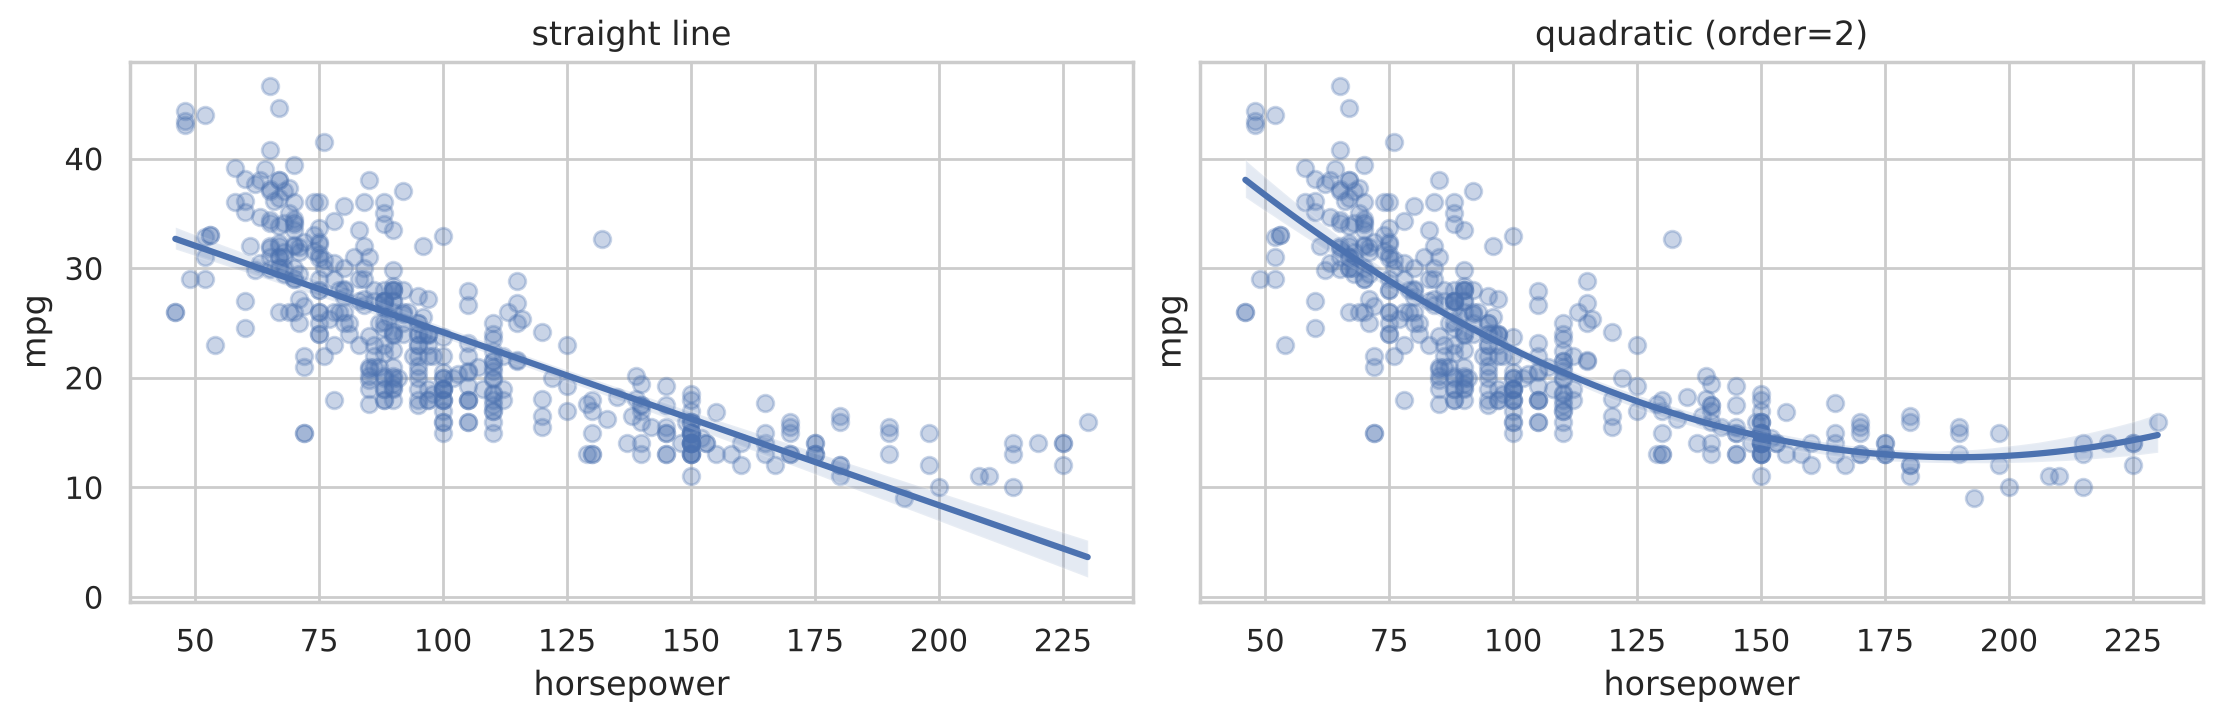

In [8]:
mpg = sns.load_dataset("mpg")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True, layout="constrained")
sns.regplot(data=mpg, x="horsepower", y="mpg", ax=axes[0], scatter_kws={"alpha": 0.3})
sns.regplot(data=mpg, x="horsepower", y="mpg", order=2, ax=axes[1], scatter_kws={"alpha": 0.3})
axes[0].set_title("straight line")
axes[1].set_title("quadratic (order=2)")
plt.show()

The straight line misses the curve: it predicts too low at both ends and too high in the middle. The
quadratic fits the pattern much better.

## lineplot: trends with uncertainty

When there are several observations per x value, `lineplot` draws the mean with a 95% confidence band.

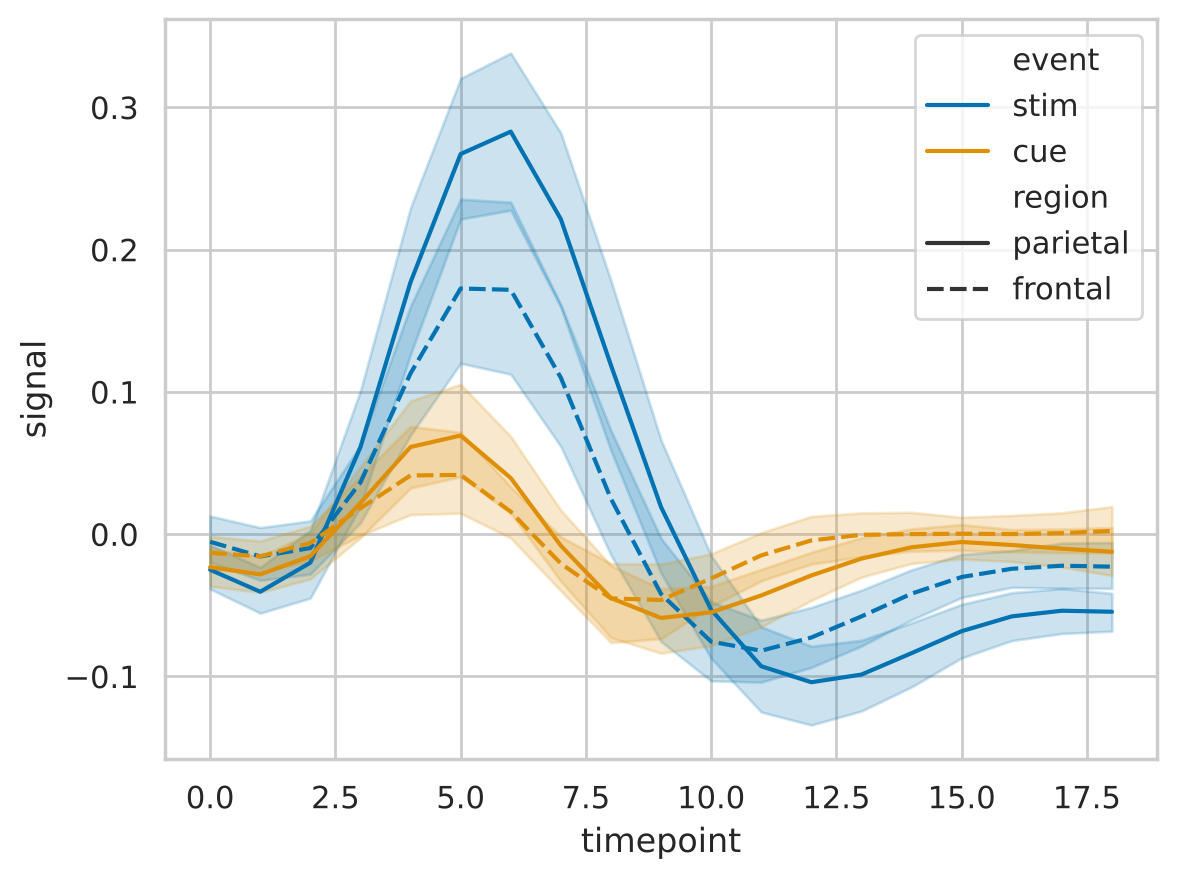

In [9]:
sns.lineplot(data=fmri, x="timepoint", y="signal", hue="event", style="region", palette="colorblind")
plt.show()

The signal peaks around timepoints 5-6 and is stronger for the "stim" event, with the parietal region
higher than the frontal region. The bands show the uncertainty in each mean across subjects.

### Time series

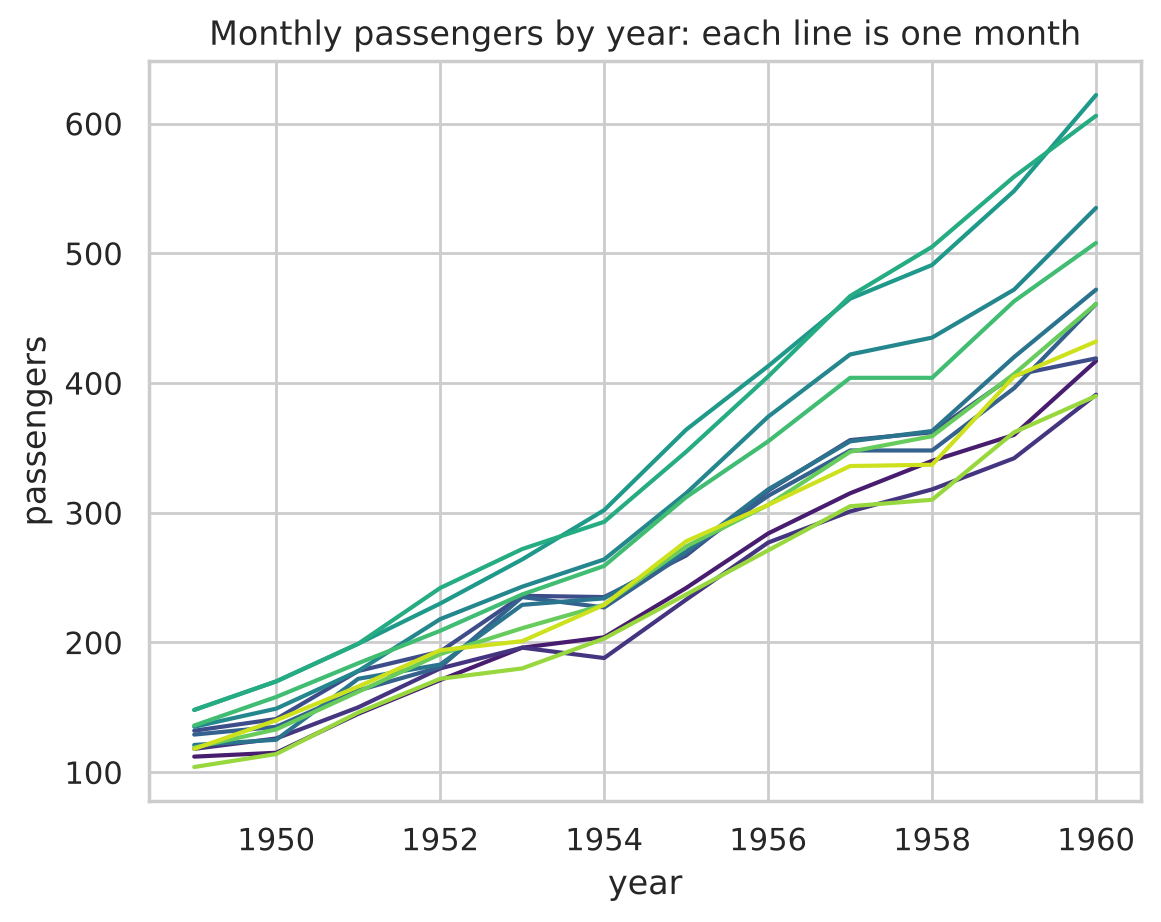

In [10]:
flights = sns.load_dataset("flights")
sns.lineplot(data=flights, x="year", y="passengers", hue="month", palette="viridis", legend=False)
plt.title("Monthly passengers by year: each line is one month")
plt.show()

A sequential palette (viridis) suits months because they are ordered.

Course data, with individual patient lines in light grey behind the group means:

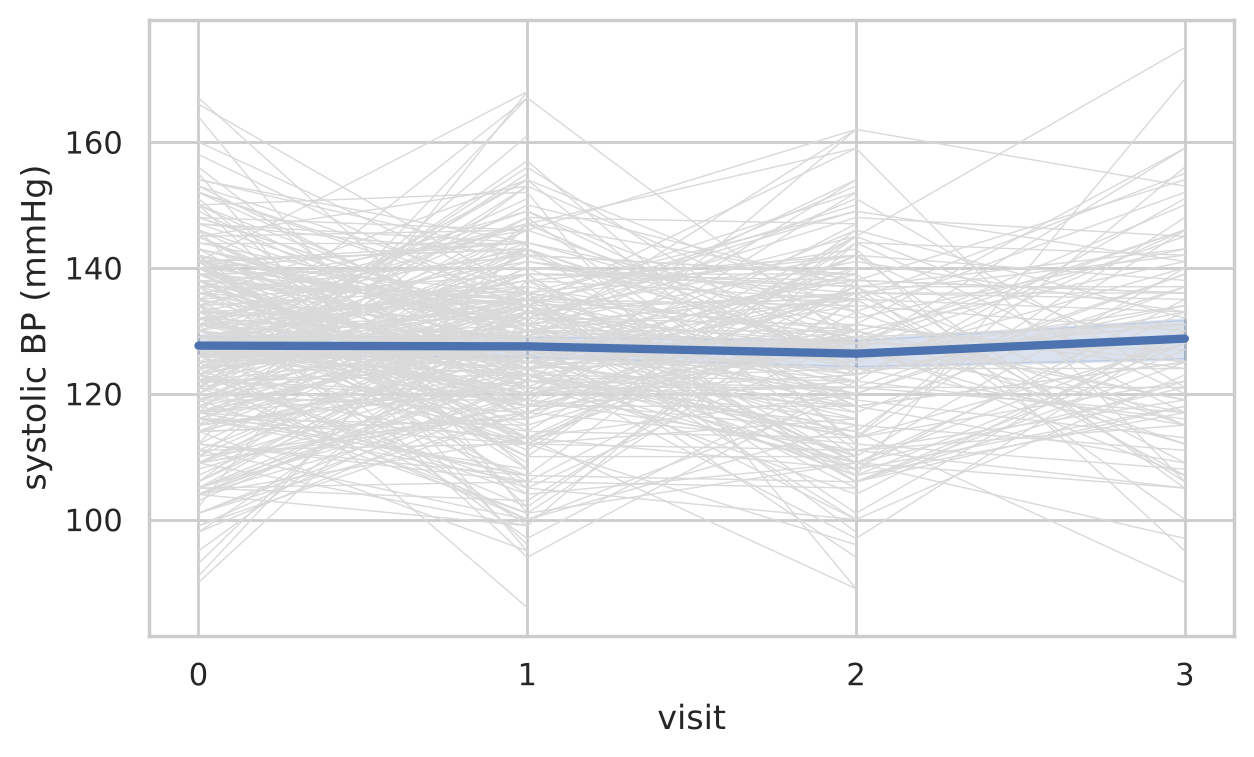

In [11]:
labs = pd.read_csv(RAW + "lab_results.csv")
fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(data=labs, x="visit", y="systolic_bp", units="patient_id", estimator=None,
             color="0.85", linewidth=0.5, ax=ax)
sns.lineplot(data=labs, x="visit", y="systolic_bp", color="C0", linewidth=3, ax=ax)
ax.set_xticks(sorted(labs["visit"].unique()))
ax.set_ylabel("systolic BP (mmHg)")
plt.show()

`units=` and `estimator=None` draw one line per patient instead of a mean, which shows how much
individuals vary around the average.

## relplot: panels

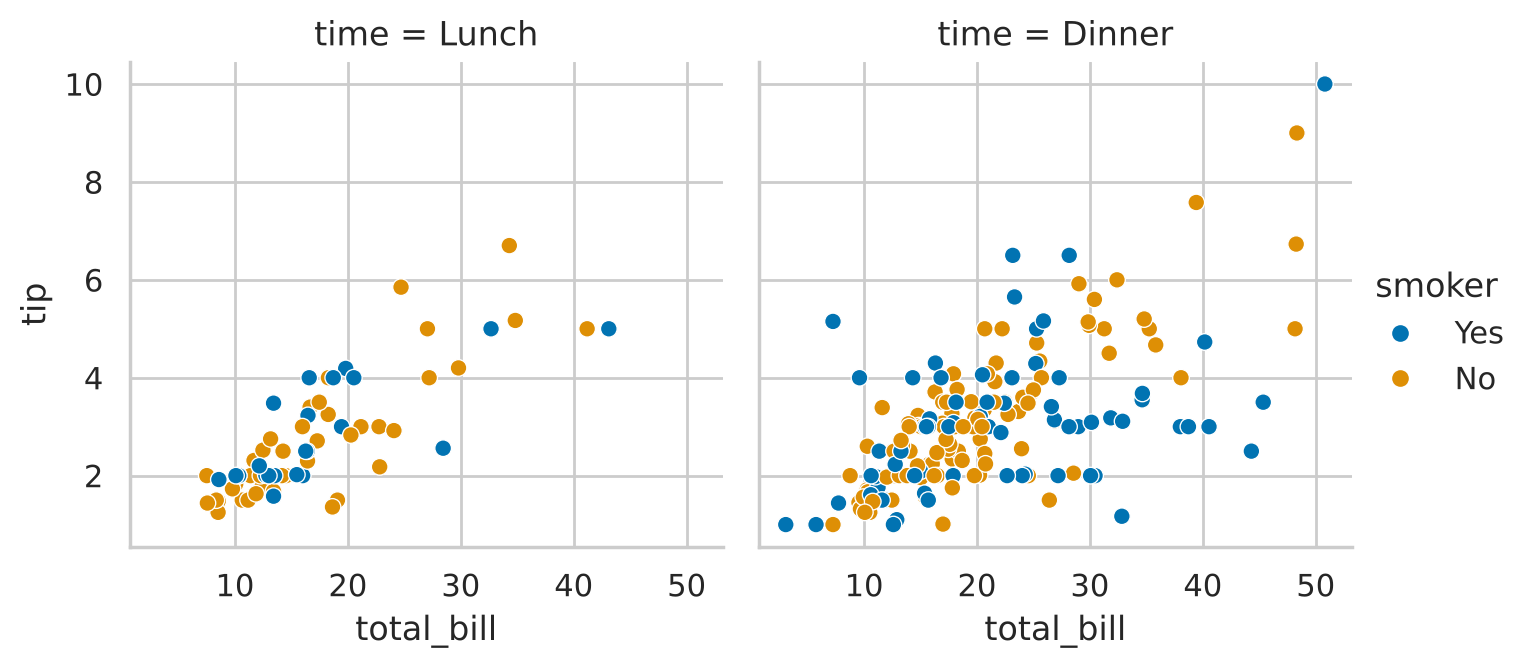

In [12]:
sns.relplot(data=tips, x="total_bill", y="tip", col="time", hue="smoker", palette="colorblind",
            height=3.5, aspect=1)
plt.show()

## jointplot: relationship plus each variable's distribution

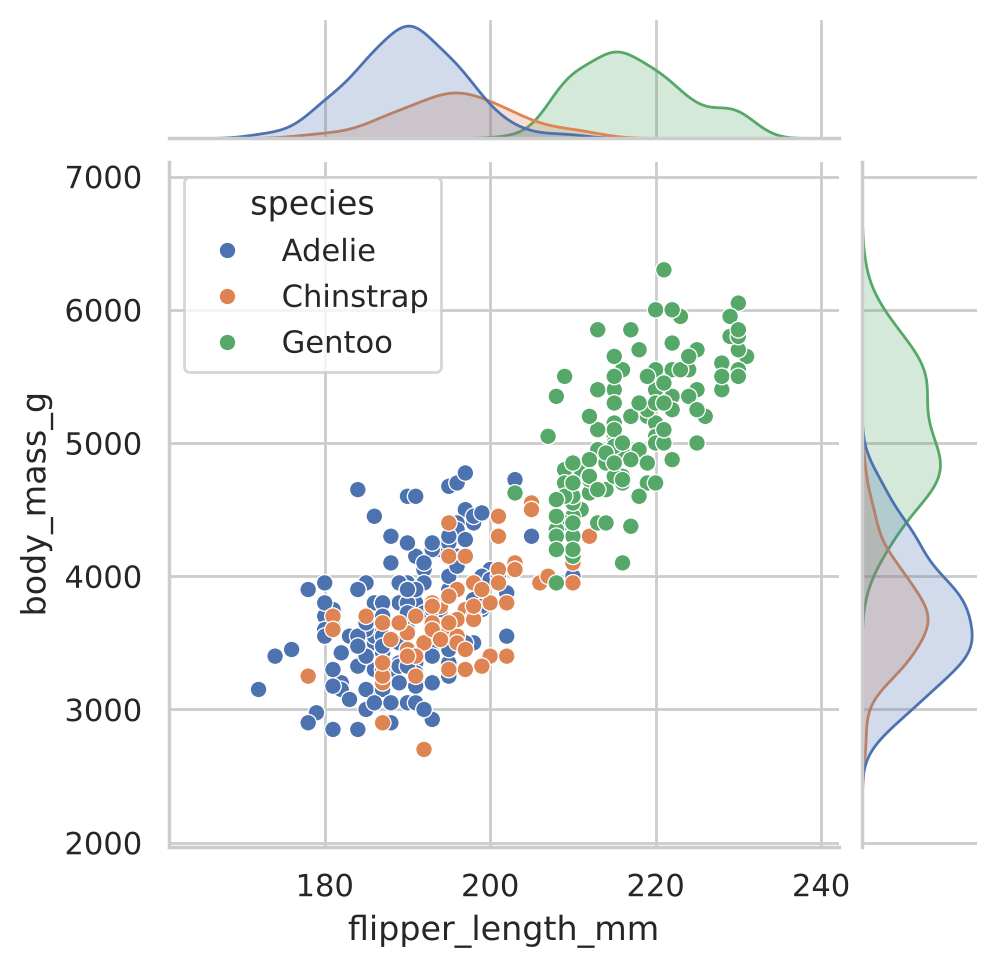

In [13]:
sns.jointplot(data=penguins, x="flipper_length_mm", y="body_mass_g", hue="species", height=5)
plt.show()

## Practise

Exercises for this folder are in `exercises/Seaborn_Exercises.ipynb`.

## Further reading

- [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html)
- [Visualising statistical relationships](https://seaborn.pydata.org/tutorial/relational.html)
- [Estimating regression fits](https://seaborn.pydata.org/tutorial/regression.html)